# 01 — Exploratory Data Analysis: Telco Customer Churn

Mục tiêu: hiểu dữ liệu để **định hướng feature engineering** cho Giai đoạn 2.

Dữ liệu: `data/processed/churn_clean.csv` (đã làm sạch ở Giai đoạn 1; 7043 dòng, 20 cột,
target `Churn` với 26.5% = 1).

> Chạy notebook từ thư mục `notebooks/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

DATA_PATH = "../data/processed/churn_clean.csv"
TARGET = "Churn"

df = pd.read_csv(DATA_PATH)
print("shape:", df.shape)
print("churn rate: {:.4f}".format(df[TARGET].mean()))
df.head()

shape: (7043, 20)
churn rate: 0.2654


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## 1. Biến số theo churn

Khách churn có `tenure` **thấp hơn nhiều** (trung vị 10 vs 38 tháng) nhưng `MonthlyCharges`
**cao hơn** (trung vị 79.65 vs 64.43). `TotalCharges` thấp hơn vì gắn bó ngắn.

In [2]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
print("Trung binh theo Churn:")
display(df.groupby(TARGET)[num_cols].mean().round(2).T)
print("Trung vi theo Churn:")
display(df.groupby(TARGET)[num_cols].median().round(2).T)

Trung binh theo Churn:


Churn,0,1
tenure,37.57,17.98
MonthlyCharges,61.27,74.44
TotalCharges,2549.91,1531.80
SeniorCitizen,0.13,0.25


Trung vi theo Churn:


Churn,0,1
tenure,38.00,10.00
MonthlyCharges,64.43,79.65
TotalCharges,1679.52,703.55
SeniorCitizen,0.00,0.00


## 2. Churn theo biến phân loại

Các khác biệt lớn nhất:
`Contract` (Month-to-month **42.7%** vs Two year **2.8%**),
`InternetService` (Fiber optic **41.9%** vs No **7.4%**),
`OnlineSecurity` / `TechSupport` (No ~42% vs Yes ~15%),
`PaymentMethod` (Electronic check **45.3%** vs automatic ~15–17%).

In [3]:
cat_cols = [c for c in df.columns if c not in num_cols + [TARGET]]

for c in cat_cols:
    grp = (df.groupby(c, observed=True)[TARGET]
             .agg(churn_pct="mean", n="count"))
    grp["churn_pct"] = (grp["churn_pct"] * 100).round(1)
    grp = grp.sort_values("churn_pct", ascending=False)
    print(f"--- {c} ---")
    display(grp)

--- gender ---


,churn_pct,n
gender,,
Female,26.9,3488
Male,26.2,3555


--- Partner ---


,churn_pct,n
Partner,,
No,33.0,3641
Yes,19.7,3402


--- Dependents ---


...

,churn_pct,n
Contract,,
Month-to-month,42.7,3875
One year,11.3,1473
Two year,2.8,1695


--- PaperlessBilling ---


,churn_pct,n
PaperlessBilling,,
Yes,33.6,4171
No,16.3,2872


--- PaymentMethod ---


,churn_pct,n
PaymentMethod,,
Electronic check,45.3,2365
Mailed check,19.1,1612
Bank transfer (automatic),16.7,1544
Credit card (automatic),15.2,1522


### Trực quan vài biến mạnh nhất

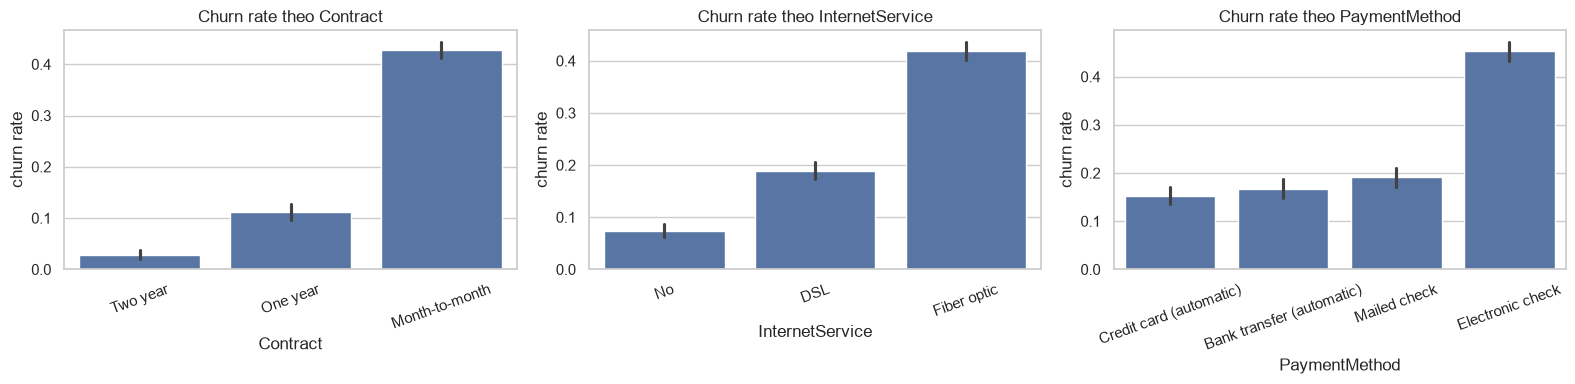

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    order = df.groupby(col)[TARGET].mean().sort_values().index
    sns.barplot(data=df, x=col, y=TARGET, order=order, ax=ax)
    ax.set_title(f"Churn rate theo {col}")
    ax.set_ylabel("churn rate")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 3. Tương quan giữa các biến số

- `tenure` tương quan **âm** với churn (-0.35) → càng gắn bó càng ít rời.
- `MonthlyCharges` tương quan **dương** (0.19).
- `TotalCharges` ≈ `tenure × MonthlyCharges` (tương quan 0.83 với `tenure`) → **đa cộng tuyến**.

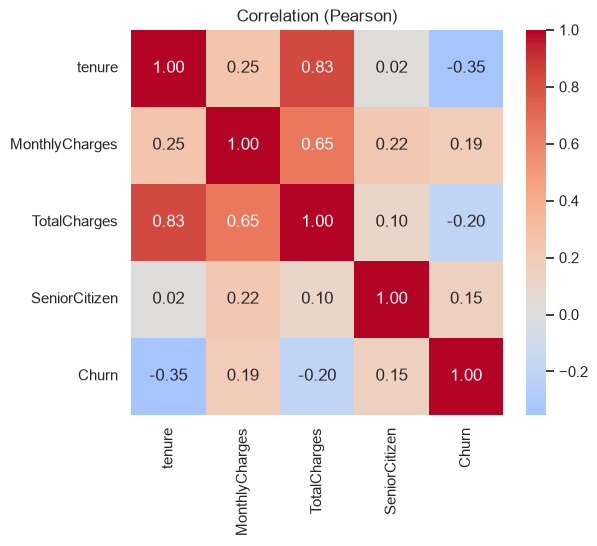

In [5]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[num_cols + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation (Pearson)")
plt.show()

## 4. Mức độ liên hệ của biến phân loại với churn (Cramér's V)

Xếp hạng: `Contract` (0.29) > `OnlineSecurity` (0.25) > `TechSupport` (0.24) >
`InternetService` (0.23) > ... Các biến **yếu**: `MultipleLines` (0.03),
`PhoneService` (0.01), `gender` (0.01) → ứng viên **loại bỏ**.

,cramers_v
Contract,0.410
OnlineSecurity,0.347
TechSupport,0.343
InternetService,0.322
PaymentMethod,0.303
OnlineBackup,0.292
DeviceProtection,0.282
StreamingMovies,0.231
StreamingTV,0.231
PaperlessBilling,0.191


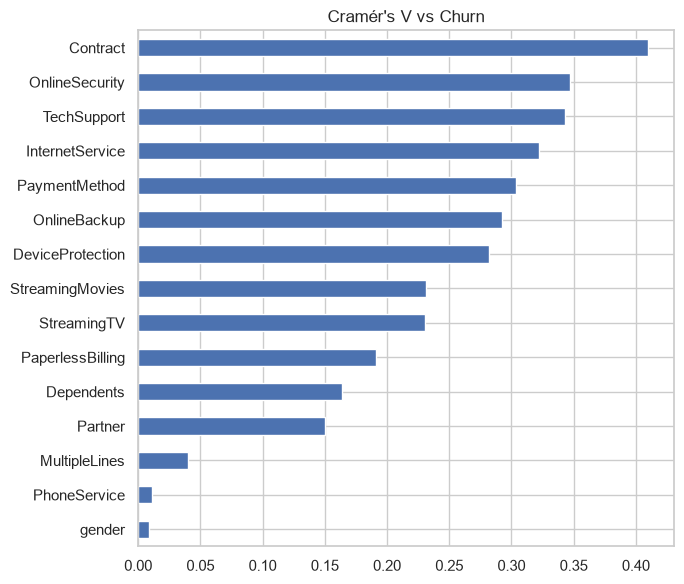

In [6]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    if min(ct.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(ct)[0]
    n = ct.sum().sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

cv = pd.Series({c: cramers_v(df[c], df[TARGET]) for c in cat_cols}).sort_values(ascending=False)
display(cv.round(3).to_frame("cramers_v"))
cv.sort_values().plot(kind="barh", figsize=(7, 6), title="Cramér's V vs Churn")
plt.tight_layout()
plt.show()

## 5. Nhóm `tenure`

Churn giảm mạnh theo thời gian gắn bó — nhóm tenure là đặc trưng hữu ích:

| Nhóm | Churn |
|------|-------|
| 0–12 | 47.4% |
| 13–24 | 28.7% |
| 25–48 | 20.4% |
| 49–72 | 9.5% |

In [7]:
df["tenure_bucket"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                             labels=["0-12", "13-24", "25-48", "49-72"])
grp = df.groupby("tenure_bucket", observed=True)[TARGET].agg(churn_pct="mean", n="count")
grp["churn_pct"] = (grp["churn_pct"] * 100).round(1)
display(grp)

,churn_pct,n
tenure_bucket,,
0-12,47.4,2186
13-24,28.7,1024
25-48,20.4,1594
49-72,9.5,2239


## 6. Ứng viên đặc trưng mới

- `num_services`: số dịch vụ đang dùng (đếm các cột = `Yes`).
- `avg_monthly_charge = TotalCharges / max(tenure, 1)` → **kiểm tra tính dư thừa**.

In [8]:
svc = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
       "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df["num_services"] = sum((df[c] == "Yes").astype(int) for c in svc)

df["avg_monthly_charge"] = df["TotalCharges"] / df["tenure"].clip(lower=1)
print("corr(num_services, Churn)     = {:.3f}".format(df["num_services"].corr(df[TARGET])))
print("corr(avg_monthly, MonthlyCharges) = {:.3f}".format(df["avg_monthly_charge"].corr(df["MonthlyCharges"])))
print("corr(avg_monthly, Churn)      = {:.3f}".format(df["avg_monthly_charge"].corr(df[TARGET])))

corr(num_services, Churn)     = -0.067
corr(avg_monthly, MonthlyCharges) = 0.994
corr(avg_monthly, Churn)      = 0.193


## 7. Kết luận & đề xuất cho `build_features.py`

**Đặc trưng nên tạo:**
1. `tenure_bucket` (0–12 / 13–24 / 25–48 / 49–72) — tín hiệu mạnh, dễ diễn giải.
2. `num_services` — độ sâu sử dụng dịch vụ (khách càng dùng nhiều càng ít rời).
3. Gộp `PaymentMethod` → `automatic` vs `manual` (Electronic check rủi ro cao rõ rệt).
4. (Cân nhắc) `Contract == "Month-to-month"` như tín hiệu rủi ro nổi bật.

**Ứng viên loại bỏ (tín hiệu yếu):** `gender`, `PhoneService`, `MultipleLines`.

**Bỏ ý tưởng `avg_monthly_charge`:** tương quan **0.994** với `MonthlyCharges` → dư thừa.

**Lưu ý đa cộng tuyến:** `TotalCharges` ≈ `tenure × MonthlyCharges` (0.83 với `tenure`) —
theo dõi khi chọn/giữ đặc trưng.

**Không có outlier** theo IQR trên `tenure`, `MonthlyCharges`, `TotalCharges`.

➡️ Các quyết định này là đầu vào cho M1 (Nhóm B — feature engineering).